In [1]:
import sagemaker, boto3, sys
print("python: ", sys.version.split()[0])
print("sagemaker SDK:", sagemaker.__version__)
print("region:", boto3.session.Session().region_name)

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


python:  3.10.20
sagemaker SDK: 2.257.5
region: eu-north-1


## Step B1 — SageMaker Setup
Establish the SageMaker session, the execution role (SageMaker assumes this IAM role to read S3 and
run training jobs), the region, and the S3 paths to the Part A outputs. Everything downstream reads
these variables.

In [2]:
import sagemaker, boto3
from sagemaker import get_execution_role

sess   = sagemaker.Session()
region = sess.boto_region_name
role   = get_execution_role()

bucket = "week6-churn-ah"   
prefix = "churn"                  # project prefix for Part B outputs (models, predictions)

print("region:", region)
print("role:  ", role)
print("bucket:", bucket)

# --- S3 inputs (from Part A) ---
train_s3     = f"s3://{bucket}/data/train.csv"
val_s3       = f"s3://{bucket}/data/validation.csv"
test_feat_s3 = f"s3://{bucket}/data/test_features.csv"

# --- S3 output location for model artifacts + batch predictions ---
output_s3 = f"s3://{bucket}/{prefix}/output"

print("\ntrain:     ", train_s3)
print("validation:", val_s3)
print("test feats:", test_feat_s3)
print("output:    ", output_s3)

region: eu-north-1
role:   arn:aws:iam::481719141347:role/service-role/AmazonSageMaker-ExecutionRole-20260812T005875
bucket: week6-churn-ah

train:      s3://week6-churn-ah/data/train.csv
validation: s3://week6-churn-ah/data/validation.csv
test feats: s3://week6-churn-ah/data/test_features.csv
output:     s3://week6-churn-ah/churn/output


## Step B2 — Define Train & Validation Channels
A "channel" tells SageMaker where an input dataset lives and what format it's in. XGBoost trains on
the train channel and scores each epoch on the validation channel (this is what drives early stopping
and HPO). Both are CSV.

In [3]:
from sagemaker.inputs import TrainingInput

train_input = TrainingInput(train_s3, content_type="text/csv")
val_input   = TrainingInput(val_s3,   content_type="text/csv")

print("channels ready:")
print("  train      ->", train_input.config["DataSource"]["S3DataSource"]["S3Uri"])
print("  validation ->", val_input.config["DataSource"]["S3DataSource"]["S3Uri"])

channels ready:
  train      -> s3://week6-churn-ah/data/train.csv
  validation -> s3://week6-churn-ah/data/validation.csv


## Step B3 — XGBoost Estimator & Static Hyperparameters
Fetch the managed SageMaker XGBoost container image, then configure an Estimator (the training-job
definition: which algorithm, what hardware, where output goes). We set the "static" hyperparameters
here — the ones we FIX. The ones we'll SEARCH over come in Step B4 (HPO).

In [ ]:
# 1) fetch the managed XGBoost container image for this region
xgb_image = sagemaker.image_uris.retrieve("xgboost", region, version="1.7-1")
print("container:", xgb_image)

# 2) define the training job (hardware + output)
xgb = sagemaker.estimator.Estimator(
    image_uri          = xgb_image,
    role               = role,
    instance_count     = 1,
    instance_type      = "ml.m5.large",   # small/cheap — fine for 3,940 rows in a shared sandbox
    volume_size        = 5,                 # GB of attached storage
    max_run            = 3600,              # safety cap: kill the job after 1h
    output_path        = output_s3,
    sagemaker_session  = sess,
)

# 3) STATIC hyperparameters (fixed for every job)
xgb.set_hyperparameters(
    objective            = "binary:logistic",  # binary classification, outputs a probability
    eval_metric          = "auc",               # score on AUC — the right metric for imbalance
    num_round            = 200,                 # max boosting rounds...
    early_stopping_rounds= 20,                  # ...but stop early if validation AUC stalls (saves cost)
    scale_pos_weight     = 4.93,                # train neg/pos ratio (3276/664) -> handles the 17% imbalance
)

print("estimator configured — ready to tune")

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/estimator.py:588: SageMakerV2DeprecationWarning: Estimator is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
Estimator is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


container: 662702820516.dkr.ecr.eu-north-1.amazonaws.com/sagemaker-xgboost:1.7-1
estimator configured — ready to tune


## Step B4 — Hyperparameter Tuning (Bayesian HPO)
Instead of guessing hyperparameters, we let SageMaker search for the best combination. We define a
RANGE for each hyperparameter, tell the tuner to maximize validation AUC, and it runs many training
jobs with different combos. Bayesian strategy uses the results of finished jobs to choose smarter
combos for the next ones.

In [ ]:
from sagemaker.tuner import HyperparameterTuner, IntegerParameter, ContinuousParameter

# the SEARCH SPACE — ranges the tuner explores (these override the static ones from B3)
hyperparameter_ranges = {
    "max_depth":        IntegerParameter(3, 8),        # tree depth: complexity vs overfitting
    "eta":              ContinuousParameter(0.05, 0.3), # learning rate (step size per tree)
    "min_child_weight": IntegerParameter(1, 10),        # min samples per leaf: higher = more conservative, lower = overfitting. min_child_weight tells the decision tree: "Do not create a new rule/branch unless there are enough customer data points backing it up
    "subsample":        ContinuousParameter(0.6, 1.0),  # row sampling per tree: fights overfitting
    "colsample_bytree": ContinuousParameter(0.6, 1.0),  # column sampling per tree
    "gamma":            ContinuousParameter(0, 5),       # min loss reduction to split: higher = simpler
}

tuner = HyperparameterTuner(
    estimator             = xgb,                 # the estimator from B3 (carries static HPs + scale_pos_weight)
    objective_metric_name = "validation:auc",    # what to optimize — AUC on the validation channel
    objective_type        = "Maximize",          # higher AUC is better
    hyperparameter_ranges = hyperparameter_ranges,
    max_jobs              = 20,                   # total training jobs to run
    max_parallel_jobs     = 3,                    # how many run at once
    strategy              = "Bayesian",           # learn from finished jobs to pick the next combo
)

# launch — reads train + validation straight from S3
tuner.fit(
    {"train": train_input, "validation": val_input},
    include_cls_metadata=False,
)

print("tuning job launched:", tuner.latest_tuning_job.name)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/tuner.py:689: SageMakerV2DeprecationWarning: HyperparameterTuner is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use the hyperparameter tuning classes under sagemaker.core.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
HyperparameterTuner is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use the hyperparameter tuning classes under sagemaker.core.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
No finished training job found associated with this estimator. Please make sure this estimator is only used for building workflow config
No finished training job found associated with this estimator. Please make sure 

........................................................................................................................................!
tuning job launched: sagemaker-xgboost-260811-2039


## Step B5 — Identify & Inspect the Best Model
The tuning job ran 20 training jobs. Now we pull the winner: its validation AUC and the exact
hyperparameters that produced it. We also pull the full results table to see how the search behaved
(did it explore the space, how much did AUC vary), and we attach the best model for Batch Transform.

In [6]:
from sagemaker.analytics import HyperparameterTuningJobAnalytics

tuner.wait()   # returns immediately if already complete

# 1) the winning training job
best_job = tuner.best_training_job()
print("best training job:", best_job)

# 2) full results table — every job, its hyperparameters, and its validation AUC
analytics = HyperparameterTuningJobAnalytics(tuner.latest_tuning_job.name)
df_results = analytics.dataframe().sort_values("FinalObjectiveValue", ascending=False)

cols = ["FinalObjectiveValue", "max_depth", "eta", "min_child_weight",
        "subsample", "colsample_bytree", "gamma", "TrainingJobName"]
print("\n--- top 10 jobs by validation AUC ---")
print(df_results[cols].head(10).to_string(index=False))

# 3) the headline number
best = df_results.iloc[0]
print(f"\nBEST validation AUC: {best['FinalObjectiveValue']:.4f}")
print(f"worst  validation AUC: {df_results['FinalObjectiveValue'].min():.4f}")

!
best training job: sagemaker-xgboost-260811-2039-010-2dd82f63

--- top 10 jobs by validation AUC ---
 FinalObjectiveValue  max_depth      eta  min_child_weight  subsample  colsample_bytree    gamma                            TrainingJobName
             0.99131        6.0 0.281621               1.0   0.901181          0.976117 0.232669 sagemaker-xgboost-260811-2039-010-2dd82f63
             0.99022        8.0 0.127962               1.0   1.000000          1.000000 1.271763 sagemaker-xgboost-260811-2039-018-cdcd6683
             0.99002        6.0 0.236357               1.0   0.888122          0.882363 1.941246 sagemaker-xgboost-260811-2039-016-4a1930c2
             0.98793        6.0 0.124810               1.0   0.944424          0.997942 0.305064 sagemaker-xgboost-260811-2039-020-3de53adf
             0.98730        6.0 0.219168               2.0   0.873830          0.981322 0.745783 sagemaker-xgboost-260811-2039-009-e83d39fb
             0.98628        6.0 0.162469               2.

In [7]:
# attach an estimator to the winning job so we can run Batch Transform in B6
best_estimator = tuner.best_estimator()
print("best model artifact (model.tar.gz):")
print(" ", best_estimator.model_data)


2026-08-11 20:47:24 Starting - Found matching resource for reuse
2026-08-11 20:47:24 Downloading - Downloading the training image
2026-08-11 20:47:24 Training - Training image download completed. Training in progress.
2026-08-11 20:47:24 Uploading - Uploading generated training model
2026-08-11 20:47:24 Completed - Resource reused by training job: sagemaker-xgboost-260811-2039-014-4078eb36
best model artifact (model.tar.gz):
  s3://week6-churn-ah/churn/output/sagemaker-xgboost-260811-2039-010-2dd82f63/output/model.tar.gz


## Step B6 — Batch Inference with Batch Transform (Cost-Sensitive)
The task asks for cost-sensitive deployment. Batch Transform spins up an instance, scores the whole
input file, writes predictions to S3, then SHUTS DOWN — you pay only for the minutes it runs. We score
test_features.csv (845 unseen customers, no labels) and get a churn probability per customer.

In [8]:
# build a Transformer from the best model (no retraining — reuses the winning model.tar.gz)
transformer = best_estimator.transformer(
    instance_count = 1,
    instance_type  = "ml.m5.large",
    output_path    = f"s3://{bucket}/{prefix}/batch-output",
    accept         = "text/csv",
    assemble_with  = "Line",     # one output line per input line
)

# run batch inference on the unseen, label-free feature file
transformer.transform(
    data         = test_feat_s3,   # s3://.../data/test_features.csv
    content_type = "text/csv",
    split_type   = "Line",         # treat each CSV line as one record to score
)
transformer.wait()

print("batch predictions written to:", transformer.output_path)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: Model is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
Model is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/transformer.py:115: SageMakerV2DeprecationWarning: Transformer is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.

...................................../miniconda3/lib/python3.9/site-packages/sagemaker_containers/_server.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-08-11:21:04:05:INFO] No GPUs detected (normal if no gpus installed)
[2026-08-11:21:04:05:INFO] No GPUs detected (normal if no gpus installed)
[2026-08-11:21:04:05:INFO] nginx config: 
worker_processes auto;
daemon off;
pid /tmp/nginx.pid;
error_log  /dev/stderr;
worker_rlimit_nofile 4096;
events {
  worker_connections 2048;
}
http {
  include /etc/nginx/mime.types;
  default_type application/octet-stream;
  access_log /dev/stdout combined;
  upstream gunicorn {
    server unix:/tmp/gunicorn.sock;
  }
  server {
    listen 8080 deferred;
    client_max_body_size 0;
    keepalive_timeout 3;
    location ~ ^/(pi

## Step B7 — Evaluate on the Untouched Test Set
Download the batch predictions (churn probabilities), pull the TRUE labels from test.csv, threshold
the probabilities into 0/1, then compute the classification metrics that matter for imbalanced data:
ROC-AUC, precision, recall, F1, plus a confusion matrix. These are the honest, unbiased numbers —
the test set never influenced training or model selection.

In [10]:
import pandas as pd, numpy as np, boto3, io

# 1) download the batch predictions from S3
s3 = boto3.client("s3")
pred_key = f"{prefix}/batch-output/test_features.csv.out"
obj = s3.get_object(Bucket=bucket, Key=pred_key)
y_proba = pd.read_csv(io.BytesIO(obj["Body"].read()), header=None)[0].values
print("predictions loaded:", y_proba.shape, "| sample:", np.round(y_proba[:5], 3))

# 2) true labels = column 0 of test.csv (the labeled test set from Part A)
test_s3 = f"s3://{bucket}/data/test.csv"       # <-- the missing definition
test_df = pd.read_csv(test_s3, header=None)
y_true  = test_df[0].values
print("true labels loaded:", y_true.shape, "| churn count:", int(y_true.sum()))

assert len(y_proba) == len(y_true), "row mismatch — predictions and labels not aligned!"
print("alignment OK:", len(y_true), "rows")

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/fsspec/registry.py:305: UserWarning: Your installed version of s3fs is very old and known to cause
severe performance issues, see also https://github.com/dask/dask/issues/10276

To fix, you should specify a lower version bound on s3fs, or
update the current installation.

  warnings.warn(s3_msg)
INFO:botocore.credentials:Found credentials from IAM Role: BaseNotebookInstanceEc2InstanceRole


predictions loaded: (845,) | sample: [0.015 0.002 0.101 0.001 0.957]
true labels loaded: (845,) | churn count: 142
alignment OK: 845 rows


In [14]:
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# ROC-AUC uses the PROBABILITIES directly (threshold-independent)
auc = roc_auc_score(y_true, y_proba)

# the other metrics need a hard 0/1 decision -> apply a threshold
threshold = 0.5
y_pred = (y_proba >= threshold).astype(int)

print(f"Test ROC-AUC : {auc:.4f}")
print(f"Precision    : {precision_score(y_true, y_pred):.4f}")
print(f"Recall       : {recall_score(y_true, y_pred):.4f}")
print(f"F1-score     : {f1_score(y_true, y_pred):.4f}")
print("\nclassification report:")
print(classification_report(y_true, y_pred, target_names=["Stayed", "Churned"]))

Test ROC-AUC : 0.9976
Precision    : 0.9577
Recall       : 0.9577
F1-score     : 0.9577

classification report:
              precision    recall  f1-score   support

      Stayed       0.99      0.99      0.99       703
     Churned       0.96      0.96      0.96       142

    accuracy                           0.99       845
   macro avg       0.97      0.97      0.97       845
weighted avg       0.99      0.99      0.99       845



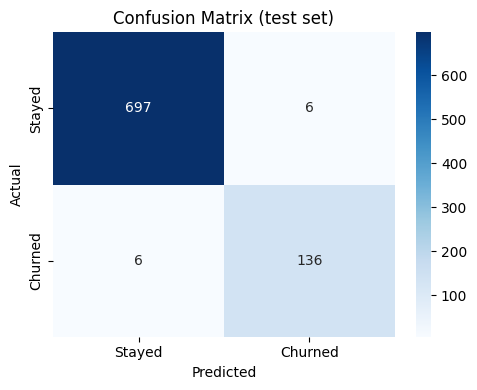

True Negatives  (correctly kept):   697
False Positives (false alarms):     6
False Negatives (MISSED churners):  6
True Positives  (caught churners):  136


In [19]:
import matplotlib.pyplot as plt, seaborn as sns

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix (test set)")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (correctly kept):   {tn}")
print(f"False Positives (false alarms):     {fp}")
print(f"False Negatives (MISSED churners):  {fn}")
print(f"True Positives  (caught churners):  {tp}")

In [18]:
!pip install seaborn